Esquema temporal de las variables utilizadas en el entrenamiento, prueba y puntuación del modelo

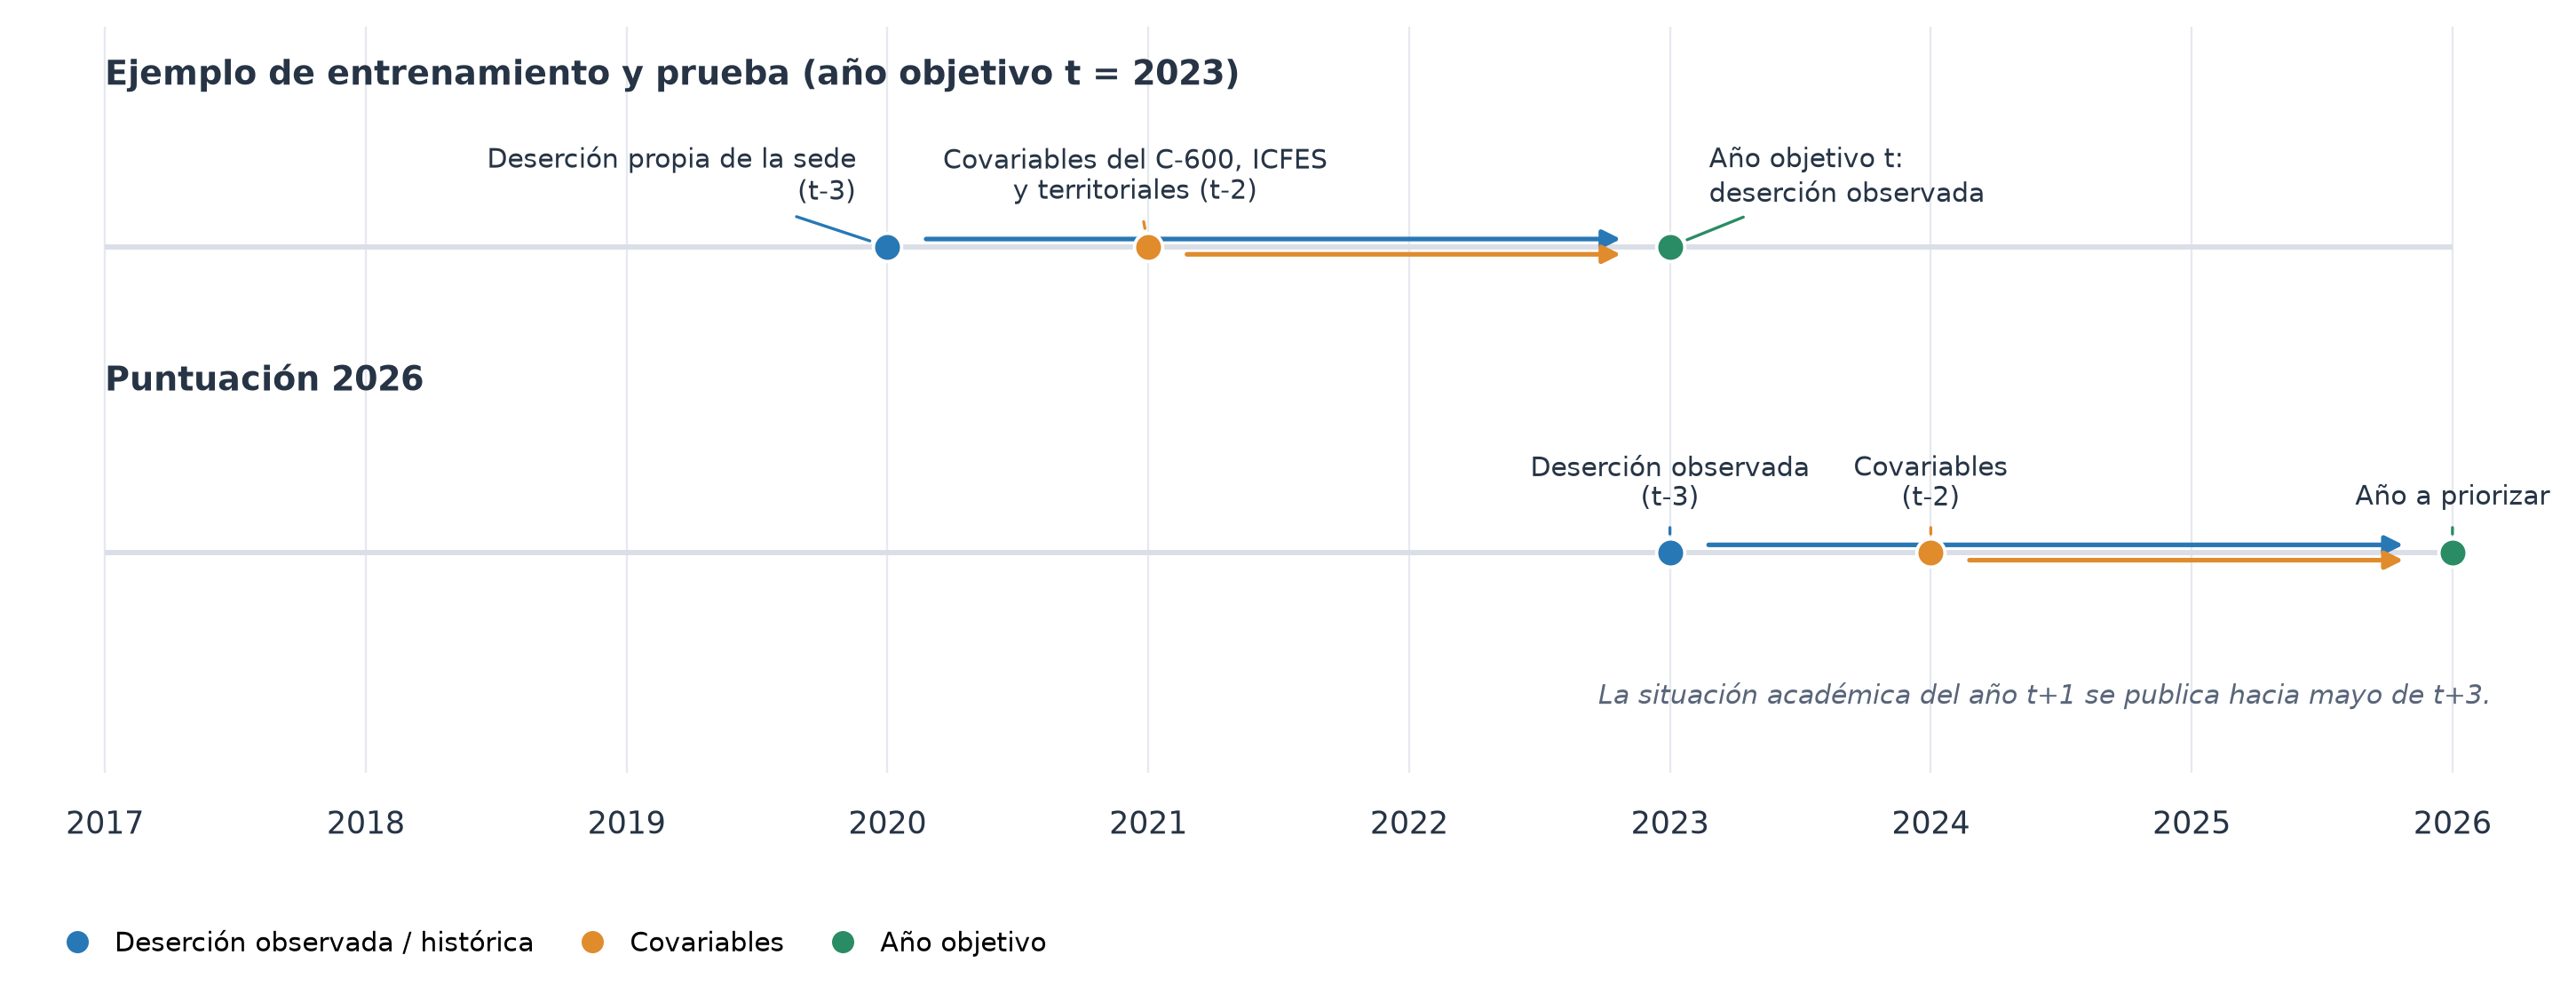

Figure successfully exported to: C:\Users\DELL\OneDrive\Escritorio\UNIVERSIDAD\Maestria Business A\Proyecto Empresarial\Figures\Grafs_Tables_Model\01_Timeline_Training_Scoring.png


In [4]:

# ============================================================
# TIMELINE: TRAINING, TESTING AND 2026 SCORING
# ============================================================

# 1. IMPORTS
import os
import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch
from matplotlib.lines import Line2D


# 2. PATHS
OUTPUT_DIR = (
    r"C:\Users\DELL\OneDrive\Escritorio\UNIVERSIDAD"
    r"\Maestria Business A\Proyecto Empresarial"
    r"\Figures\Grafs_Tables_Model"
)

OUTPUT_FILE = os.path.join(
    OUTPUT_DIR,
    "01_Timeline_Training_Scoring.png"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)


# 3. GENERAL SETTINGS
FIGSIZE = (10, 4)
DPI = 300

YEARS = list(range(2017, 2027))

COLORS = {
    "dropout": "#2878B5",
    "covariates": "#E08B2C",
    "target": "#2A8C65",
    "grid": "#D9DEE7",
    "text": "#263445"
}


# 4. HELPER FUNCTIONS
def add_marker(ax, year, y, color, label,
               text_x, text_y, alignment="center"):

    # Draw timeline marker
    ax.scatter(
        year, y,
        s=58,
        color=color,
        edgecolor="white",
        linewidth=0.9,
        zorder=4
    )

    # Add marker label
    ax.annotate(
        label,
        xy=(year, y),
        xytext=(text_x, text_y),
        ha=alignment,
        va="bottom",
        fontsize=7.1,
        color=COLORS["text"],
        linespacing=1.2,
        arrowprops={
            "arrowstyle": "-",
            "color": color,
            "linewidth": 0.8,
            "shrinkA": 2,
            "shrinkB": 5
        }
    )


def add_arrow(ax, start, end, y, color, vertical_offset=0):

    # Draw directional arrow towards the target year
    arrow = FancyArrowPatch(
        (start + 0.12, y + vertical_offset),
        (end - 0.16, y + vertical_offset),
        arrowstyle="-|>",
        mutation_scale=10,
        linewidth=1.25,
        color=color,
        zorder=2
    )

    ax.add_patch(arrow)


# 5. FIGURE CREATION
fig, ax = plt.subplots(figsize=FIGSIZE, dpi=DPI)

y_train = 1.0
y_score = 0.0

ax.set_xlim(2016.7, 2026.3)
ax.set_ylim(-0.72, 1.72)


# 6. TIMELINE AXES
for y in [y_train, y_score]:
    ax.hlines(
        y,
        2017,
        2026,
        color=COLORS["grid"],
        linewidth=1.4,
        zorder=1
    )

ax.set_xticks(YEARS)
ax.set_xticklabels(
    YEARS,
    fontsize=8.5,
    color=COLORS["text"]
)

ax.set_yticks([])
ax.tick_params(axis="x", length=0, pad=10)


# 7. ROW TITLES
ax.text(
    2017,
    1.56,
    "Ejemplo de entrenamiento y prueba (año objetivo t = 2023)",
    fontsize=9.2,
    fontweight="bold",
    color=COLORS["text"],
    ha="left",
    va="center"
)

ax.text(
    2017,
    0.56,
    "Puntuación 2026",
    fontsize=9.2,
    fontweight="bold",
    color=COLORS["text"],
    ha="left",
    va="center"
)


# 8. ROW 1: TRAINING AND TEST EXAMPLE
# Target year: 2023

# Arrows pointing towards the target year
add_arrow(ax, 2020, 2023, y_train, COLORS["dropout"], 0.025)
add_arrow(ax, 2021, 2023, y_train, COLORS["covariates"], -0.025)

# Historical dropout: t-3
add_marker(
    ax, 2020, y_train,
    COLORS["dropout"],
    "Deserción propia de la sede\n(t-3)",
    2019.88, 1.13,
    "right"
)

# Covariates: t-2
add_marker(
    ax, 2021, y_train,
    COLORS["covariates"],
    "Covariables del C-600, ICFES\ny territoriales (t-2)",
    2020.95, 1.13,
    "center"
)

# Observed target
add_marker(
    ax, 2023, y_train,
    COLORS["target"],
    "Año objetivo t:\ndeserción observada",
    2023.15, 1.13,
    "left"
)


# 9. ROW 2: SCORING 2026

# Arrows pointing towards the prioritization year
add_arrow(ax, 2023, 2026, y_score, COLORS["dropout"], 0.025)
add_arrow(ax, 2024, 2026, y_score, COLORS["covariates"], -0.025)

# Historical dropout: t-3
add_marker(
    ax, 2023, y_score,
    COLORS["dropout"],
    "Deserción observada\n(t-3)",
    2023, 0.13,
    "center"
)

# Covariates: t-2
add_marker(
    ax, 2024, y_score,
    COLORS["covariates"],
    "Covariables\n(t-2)",
    2024, 0.13,
    "center"
)

# Prioritization year
add_marker(
    ax, 2026, y_score,
    COLORS["target"],
    "Año a priorizar",
    2026, 0.13,
    "center"
)


# 10. PUBLICATION TIMING ANNOTATION
ax.text(
    2026.15,
    -0.47,
    "La situación académica del año t+1 se publica hacia mayo de t+3.",
    ha="right",
    va="center",
    fontsize=7.1,
    color="#596579",
    style="italic"
)


# 11. LEGEND
legend_items = [
    Line2D(
        [0], [0],
        marker="o",
        color="none",
        markerfacecolor=COLORS["dropout"],
        markeredgecolor="white",
        markersize=7,
        label="Deserción observada / histórica"
    ),
    Line2D(
        [0], [0],
        marker="o",
        color="none",
        markerfacecolor=COLORS["covariates"],
        markeredgecolor="white",
        markersize=7,
        label="Covariables"
    ),
    Line2D(
        [0], [0],
        marker="o",
        color="none",
        markerfacecolor=COLORS["target"],
        markeredgecolor="white",
        markersize=7,
        label="Año objetivo"
    )
]

ax.legend(
    handles=legend_items,
    loc="lower left",
    bbox_to_anchor=(0.0, -0.28),
    ncol=3,
    frameon=False,
    fontsize=7.2,
    handletextpad=0.4,
    columnspacing=1.2
)


# 12. FINAL FORMATTING
for spine in ax.spines.values():
    spine.set_visible(False)

ax.grid(
    axis="x",
    color=COLORS["grid"],
    linewidth=0.55,
    alpha=0.65
)

ax.set_axisbelow(True)

fig.subplots_adjust(
    left=0.045,
    right=0.985,
    top=0.94,
    bottom=0.24
)


# 13. EXPORT
fig.savefig(
    OUTPUT_FILE,
    dpi=DPI,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print(f"Figure successfully exported to: {OUTPUT_FILE}")


Evolución de la deserción escolar y de la proporción de sedes sin deserción observada, según tipo de oferta educativa, 2017-2024

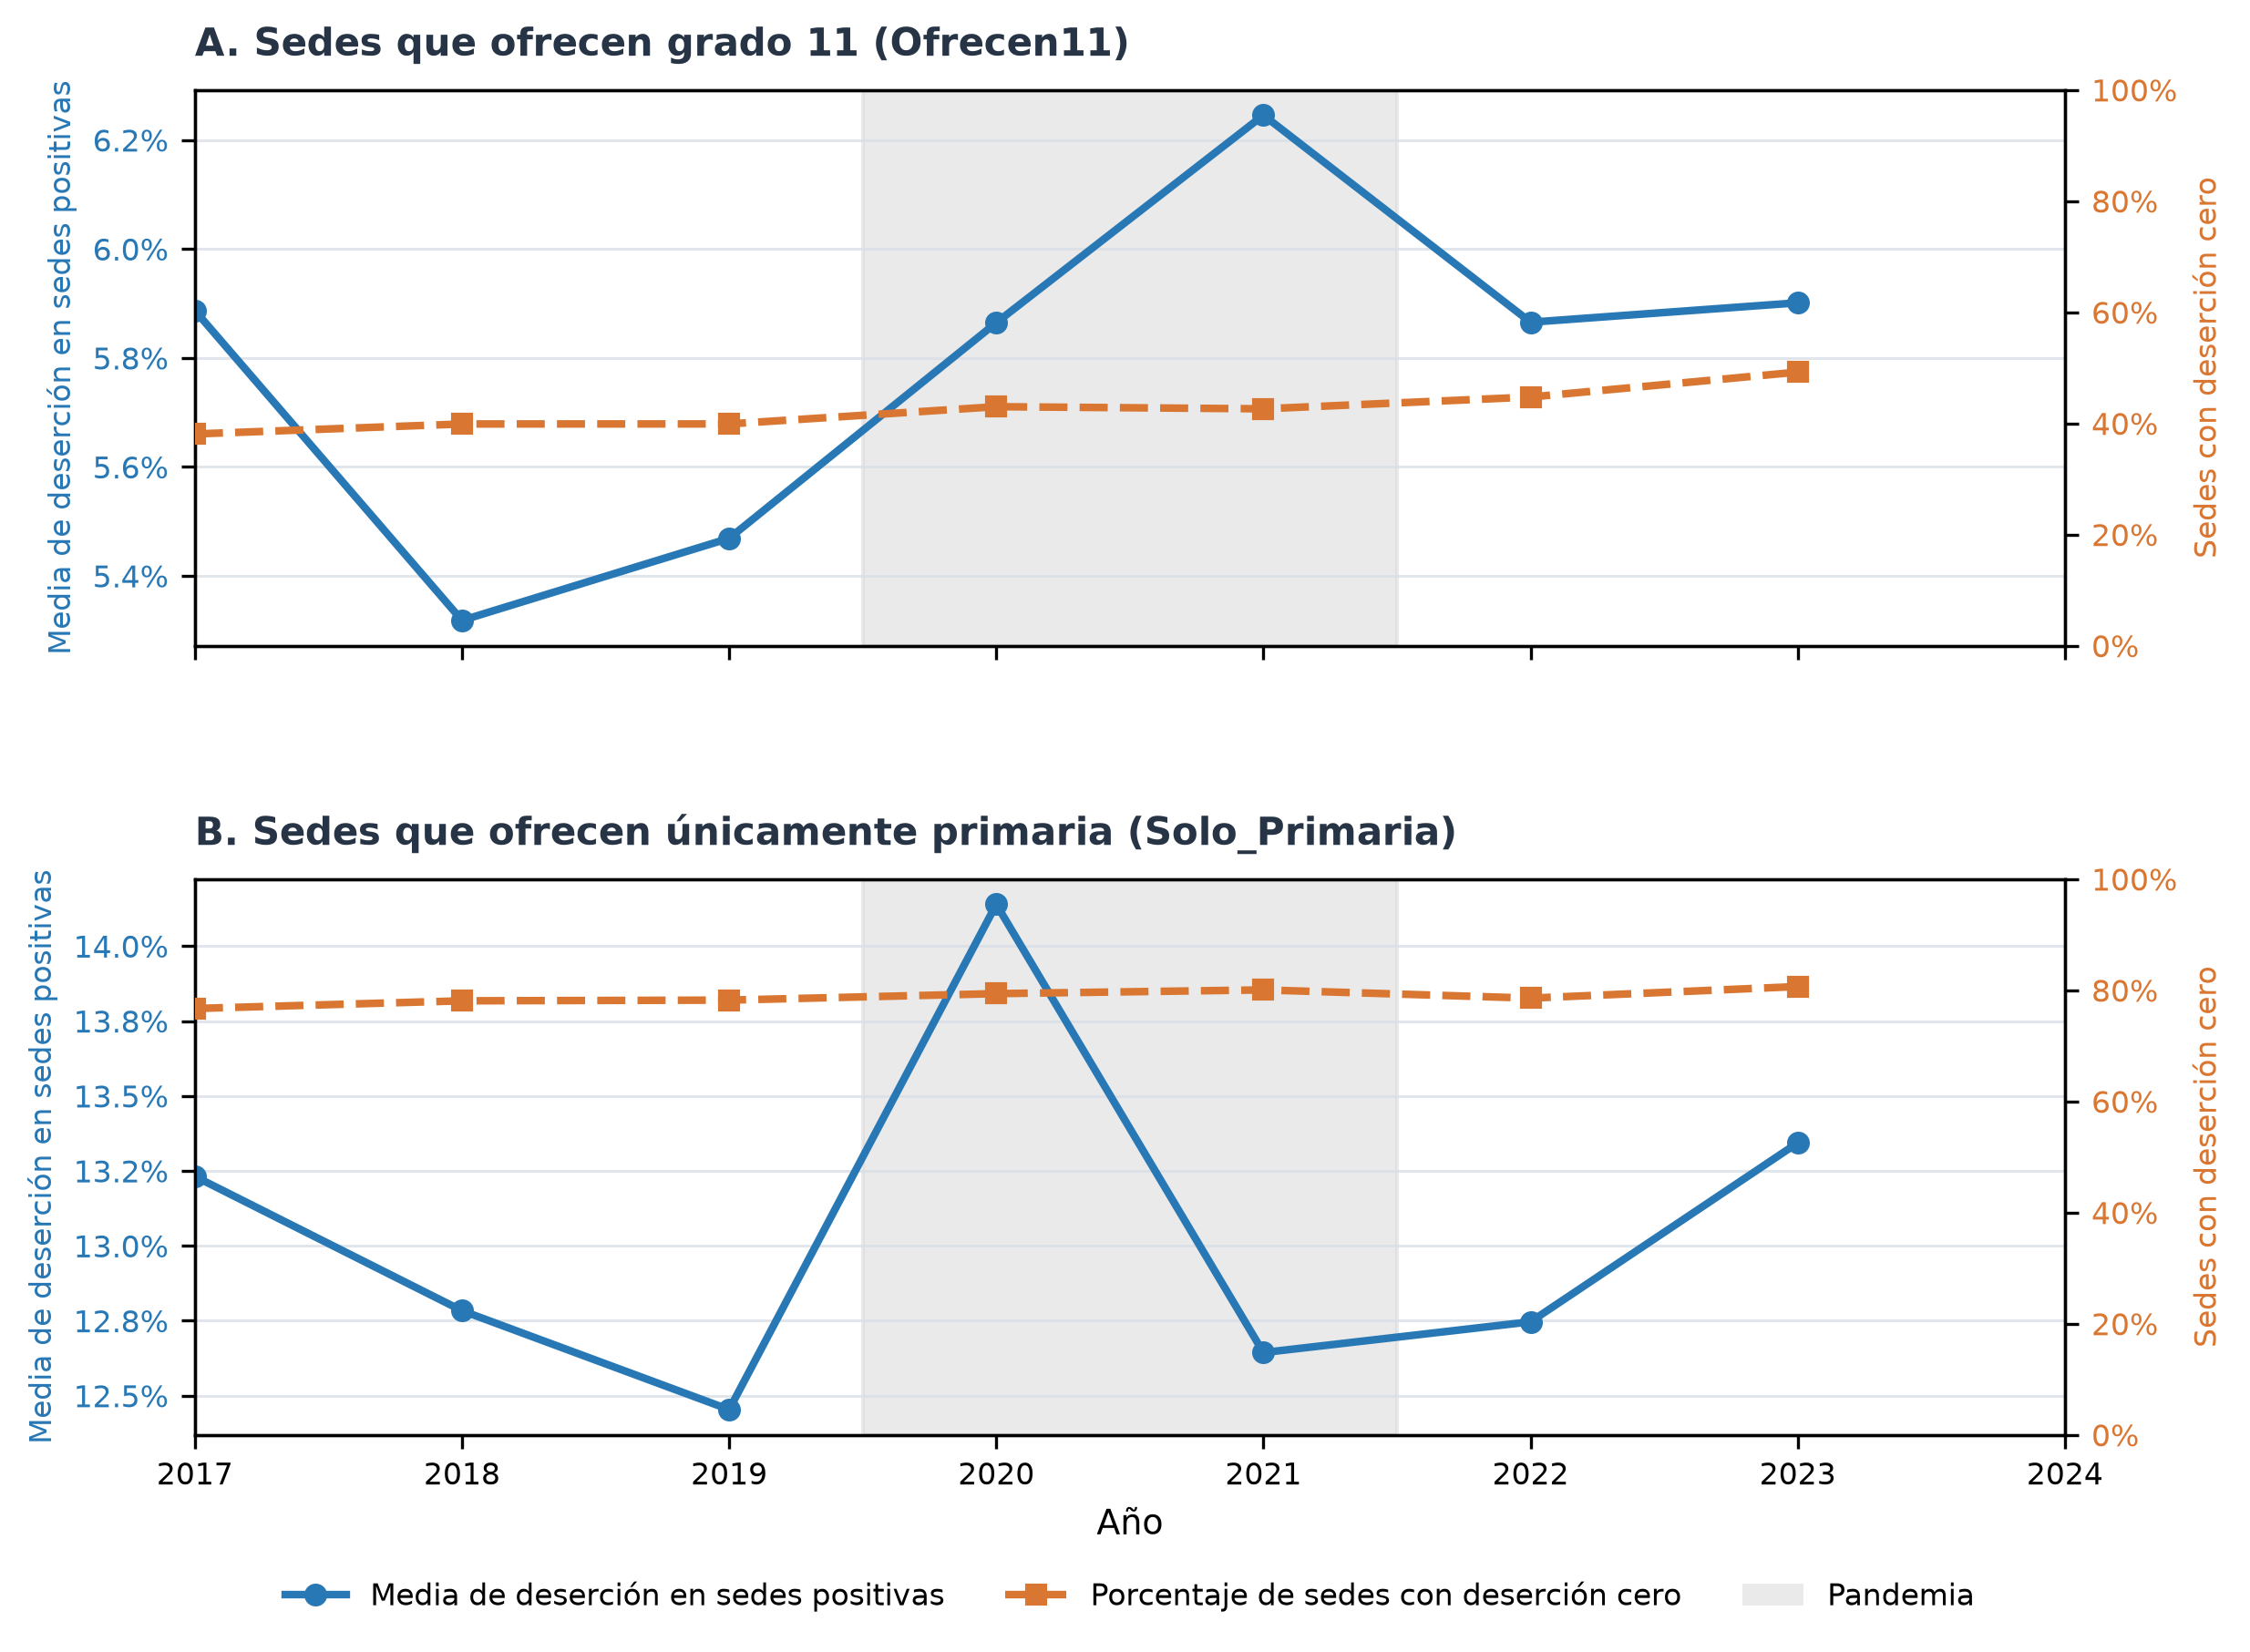


ANNUAL DROPOUT STATISTICS

PANEL: Ofrecen11
---------------------------------------------------------------------------
2017: N=12,295 | Media positiva=5.89% | Ceros=38.09% | Ceros imputados=256
2018: N=12,349 | Media positiva=5.32% | Ceros=39.89% | Ceros imputados=269
2019: N=12,557 | Media positiva=5.47% | Ceros=39.90% | Ceros imputados=149
2020: N=12,679 | Media positiva=5.86% | Ceros=43.00% | Ceros imputados=279
2021: N=12,648 | Media positiva=6.25% | Ceros=42.62% | Ceros imputados=256
2022: N=12,678 | Media positiva=5.87% | Ceros=44.74% | Ceros imputados=255
2023: N=12,647 | Media positiva=5.90% | Ceros=49.22% | Ceros imputados=614
2024: N=0 | Media positiva=N/A | Ceros=N/A | Ceros imputados=0

PANEL: Solo_Primaria
---------------------------------------------------------------------------
2017: N=41,000 | Media positiva=13.23% | Ceros=76.71% | Ceros imputados=6,384
2018: N=40,853 | Media positiva=12.78% | Ceros=78.09% | Ceros imputados=7,100
2019: N=40,970 | Media positiva=12.45

In [6]:

# ============================================================
# FIGURE: SCHOOL DROPOUT TRENDS BY SCHOOL PANEL (2017-2024)
# ============================================================

# 1. IMPORTS
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

from matplotlib.patches import Patch
from matplotlib.lines import Line2D


# ============================================================
# 2. PATHS
# ============================================================

DATA_DIR = (
    r"C:\Users\DELL\OneDrive\Escritorio\UNIVERSIDAD"
    r"\Maestria Business A\Proyecto Empresarial"
    r"\Data\Processed"
)

OUTPUT_DIR = (
    r"C:\Users\DELL\OneDrive\Escritorio\UNIVERSIDAD"
    r"\Maestria Business A\Proyecto Empresarial"
    r"\Figures\Grafs_Tables_Model"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

FILE_OFRECEN11 = os.path.join(
    DATA_DIR, "panel_maestro_ofrecen11.csv"
)

FILE_SOLO_PRIMARIA = os.path.join(
    DATA_DIR, "panel_maestro_Solo_Primaria.csv"
)

OUTPUT_FIGURE = os.path.join(
    OUTPUT_DIR, "02_Tendencia_Desercion_Paneles_Maestros.png"
)

OUTPUT_TABLE = os.path.join(
    OUTPUT_DIR, "02_Tendencia_Desercion_Valores_Anuales.csv"
)


# ============================================================
# 3. GENERAL SETTINGS
# ============================================================

YEARS = list(range(2017, 2025))

FIGSIZE = (9, 6)
DPI = 300

# Column names confirmed in the sample workbook
YEAR_COL = "PERIODO_ANIO"
RATE_COL = "TASA_DESERCION_SEDE"
SCHOOL_COL = "SEDE_CODIGO"
IMPUTED_ZERO_COL = "FLAG_DESERCION_SEDE_CERO_IMPUTADO"

COLORS = {
    "positive_mean": "#2878B5",
    "zero_percentage": "#D97732",
    "pandemic": "#D9D9D9",
    "text": "#263445",
    "grid": "#D9DEE7"
}


# ============================================================
# 4. DATA LOADING
# ============================================================

def load_panel(file_path, panel_name):

    # Check whether the input file exists
    if not os.path.exists(file_path):
        raise FileNotFoundError(
            f"Input file not found: {file_path}"
        )

    # Read CSV while preserving school identifiers
    df = pd.read_csv(
        file_path,
        dtype={SCHOOL_COL: str},
        low_memory=False
    )

    # Validate required columns
    required_columns = [
        YEAR_COL,
        RATE_COL,
        SCHOOL_COL,
        IMPUTED_ZERO_COL
    ]

    missing_columns = [
        col for col in required_columns
        if col not in df.columns
    ]

    if missing_columns:
        raise ValueError(
            f"{panel_name}: Missing columns: {missing_columns}"
        )

    # Convert analytical variables to numeric
    df[YEAR_COL] = pd.to_numeric(
        df[YEAR_COL], errors="coerce"
    )

    df[RATE_COL] = pd.to_numeric(
        df[RATE_COL], errors="coerce"
    )

    df[IMPUTED_ZERO_COL] = pd.to_numeric(
        df[IMPUTED_ZERO_COL], errors="coerce"
    )

    # Keep the requested observation period
    df = df[df[YEAR_COL].isin(YEARS)].copy()

    # Validate that each school has only one record per year
    duplicated = df.duplicated(
        subset=[SCHOOL_COL, YEAR_COL],
        keep=False
    )

    if duplicated.any():
        examples = df.loc[
            duplicated, [SCHOOL_COL, YEAR_COL]
        ].head(10)

        raise ValueError(
            f"{panel_name}: Duplicate school-year records found.\n"
            f"Examples:\n{examples.to_string(index=False)}"
        )

    # Exclude observations without an available dropout rate
    df = df.dropna(subset=[RATE_COL, YEAR_COL]).copy()

    # Validate dropout rates
    if ((df[RATE_COL] < 0) | (df[RATE_COL] > 1)).any():
        raise ValueError(
            f"{panel_name}: Dropout rates outside the [0, 1] range."
        )

    return df


# ============================================================
# 5. ANNUAL STATISTICS
# ============================================================

def calculate_annual_statistics(df, panel_name):

    records = []

    for year in YEARS:

        year_df = df[df[YEAR_COL] == year].copy()

        n_schools = len(year_df)

        if n_schools == 0:
            records.append({
                "PANEL": panel_name,
                "YEAR": year,
                "N_SEDES": 0,
                "N_SEDES_POSITIVAS": 0,
                "N_SEDES_CERO": 0,
                "N_CEROS_IMPUTADOS": 0,
                "MEAN_POSITIVE_DROPOUT": np.nan,
                "PCT_ZERO_DROPOUT": np.nan
            })
            continue

        # Identify positive and zero dropout rates
        positive_rates = year_df.loc[
            year_df[RATE_COL] > 0, RATE_COL
        ]

        zero_schools = year_df[RATE_COL] == 0

        # Count imputed zeros among all zero observations
        imputed_zeros = (
            zero_schools
            & (year_df[IMPUTED_ZERO_COL] == 1)
        ).sum()

        # Calculate annual statistics
        mean_positive = (
            positive_rates.mean()
            if len(positive_rates) > 0
            else np.nan
        )

        pct_zero = zero_schools.mean() * 100

        records.append({
            "PANEL": panel_name,
            "YEAR": year,
            "N_SEDES": n_schools,
            "N_SEDES_POSITIVAS": len(positive_rates),
            "N_SEDES_CERO": int(zero_schools.sum()),
            "N_CEROS_IMPUTADOS": int(imputed_zeros),
            "MEAN_POSITIVE_DROPOUT": mean_positive,
            "PCT_ZERO_DROPOUT": pct_zero
        })

    return pd.DataFrame(records)


# ============================================================
# 6. PLOT FUNCTION
# ============================================================

def plot_panel(ax, df_stats, panel_title):

    # Create the secondary axis
    ax_right = ax.twinx()

    years = df_stats["YEAR"]

    mean_positive = df_stats[
        "MEAN_POSITIVE_DROPOUT"
    ]

    pct_zero = df_stats[
        "PCT_ZERO_DROPOUT"
    ]

    # Highlight pandemic years: 2020 and 2021
    ax.axvspan(
        2019.5,
        2021.5,
        color=COLORS["pandemic"],
        alpha=0.55,
        zorder=0
    )

    # Left axis: mean dropout rate among positive schools
    ax.plot(
        years,
        mean_positive,
        color=COLORS["positive_mean"],
        linewidth=2,
        marker="o",
        markersize=5,
        label="Media de deserción en sedes positivas",
        zorder=3
    )

    # Right axis: percentage of schools with zero dropout
    ax_right.plot(
        years,
        pct_zero,
        color=COLORS["zero_percentage"],
        linewidth=2,
        marker="s",
        markersize=5,
        linestyle="--",
        label="Sedes con deserción cero",
        zorder=3
    )

    # Panel title
    ax.set_title(
        panel_title,
        fontsize=10,
        fontweight="bold",
        color=COLORS["text"],
        loc="left",
        pad=9
    )

    # X-axis
    ax.set_xlim(2017, 2024)
    ax.set_xticks(YEARS)
    ax.set_xticklabels(YEARS, fontsize=8)

    # Left Y-axis
    ax.yaxis.set_major_formatter(
        mtick.PercentFormatter(xmax=1, decimals=1)
    )

    ax.set_ylabel(
        "Media de deserción en sedes positivas",
        fontsize=8,
        color=COLORS["positive_mean"]
    )

    ax.tick_params(
        axis="y",
        labelcolor=COLORS["positive_mean"],
        labelsize=8
    )

    # Right Y-axis
    ax_right.set_ylim(0, 100)

    ax_right.yaxis.set_major_formatter(
        mtick.PercentFormatter(xmax=100, decimals=0)
    )

    ax_right.set_ylabel(
        "Sedes con deserción cero",
        fontsize=8,
        color=COLORS["zero_percentage"]
    )

    ax_right.tick_params(
        axis="y",
        labelcolor=COLORS["zero_percentage"],
        labelsize=8
    )

    # Grid and formatting
    ax.grid(
        axis="y",
        color=COLORS["grid"],
        linewidth=0.7,
        alpha=0.8
    )

    ax.set_axisbelow(True)

    return ax_right


# ============================================================
# 7. MAIN EXECUTION
# ============================================================

# Load both master panels
df_ofrecen11 = load_panel(
    FILE_OFRECEN11,
    "Ofrecen11"
)

df_solo_primaria = load_panel(
    FILE_SOLO_PRIMARIA,
    "Solo_Primaria"
)

# Calculate annual statistics
stats_ofrecen11 = calculate_annual_statistics(
    df_ofrecen11,
    "Ofrecen11"
)

stats_solo_primaria = calculate_annual_statistics(
    df_solo_primaria,
    "Solo_Primaria"
)

# Combine annual statistics
stats_all = pd.concat(
    [stats_ofrecen11, stats_solo_primaria],
    ignore_index=True
)

# Export annual statistics
stats_all.to_csv(
    OUTPUT_TABLE,
    index=False,
    encoding="utf-8-sig"
)


# ============================================================
# 8. FIGURE
# ============================================================

fig, axes = plt.subplots(
    nrows=2,
    ncols=1,
    figsize=FIGSIZE,
    dpi=DPI,
    sharex=True
)

# First panel: schools offering grade 11
plot_panel(
    axes[0],
    stats_ofrecen11,
    "A. Sedes que ofrecen grado 11 (Ofrecen11)"
)

# Second panel: primary-only schools
plot_panel(
    axes[1],
    stats_solo_primaria,
    "B. Sedes que ofrecen únicamente primaria (Solo_Primaria)"
)

# Common X-axis label
axes[1].set_xlabel(
    "Año",
    fontsize=9
)

# Shared legend
legend_elements = [
    Line2D(
        [0], [0],
        color=COLORS["positive_mean"],
        marker="o",
        linewidth=2,
        markersize=5,
        label="Media de deserción en sedes positivas"
    ),
    Line2D(
        [0], [0],
        color=COLORS["zero_percentage"],
        marker="s",
        linestyle="--",
        linewidth=2,
        markersize=5,
        label="Porcentaje de sedes con deserción cero"
    ),
    Patch(
        facecolor=COLORS["pandemic"],
        alpha=0.55,
        label="Pandemia"
    )
]

fig.legend(
    handles=legend_elements,
    loc="lower center",
    bbox_to_anchor=(0.5, 0.005),
    ncol=3,
    frameon=False,
    fontsize=8
)

# Final layout
fig.subplots_adjust(
    left=0.12,
    right=0.88,
    top=0.95,
    bottom=0.13,
    hspace=0.42
)

# Export figure
fig.savefig(
    OUTPUT_FIGURE,
    dpi=DPI,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()


# ============================================================
# 9. PRINT RESULTS FOR THESIS WRITING
# ============================================================

print("\n" + "=" * 75)
print("ANNUAL DROPOUT STATISTICS")
print("=" * 75)

for panel_name in ["Ofrecen11", "Solo_Primaria"]:

    panel_stats = stats_all[
        stats_all["PANEL"] == panel_name
    ].copy()

    print(f"\nPANEL: {panel_name}")
    print("-" * 75)

    for _, row in panel_stats.iterrows():

        mean_value = row["MEAN_POSITIVE_DROPOUT"]
        zero_value = row["PCT_ZERO_DROPOUT"]

        mean_text = (
            f"{mean_value * 100:.2f}%"
            if pd.notna(mean_value)
            else "N/A"
        )

        zero_text = (
            f"{zero_value:.2f}%"
            if pd.notna(zero_value)
            else "N/A"
        )

        print(
            f"{int(row['YEAR'])}: "
            f"N={int(row['N_SEDES']):,} | "
            f"Media positiva={mean_text} | "
            f"Ceros={zero_text} | "
            f"Ceros imputados={int(row['N_CEROS_IMPUTADOS']):,}"
        )

print("\n" + "=" * 75)
print("OUTPUT FILES")
print("=" * 75)

print(f"Figure: {OUTPUT_FIGURE}")
print(f"Annual statistics: {OUTPUT_TABLE}")


Asociación de variables con la variable objetivo

In [9]:

# ============================================================
# 00_COD_Other_Figures
# Spearman correlation of lagged predictors with school dropout
# ============================================================


# ============================================================
# 1. PATHS
# ============================================================

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D


PROJECT_DIR = Path(
    r"C:\Users\DELL\OneDrive\Escritorio\UNIVERSIDAD\Maestria Business A\Proyecto Empresarial"
)

DATA_DIR = PROJECT_DIR / "Data" / "Processed"

OUTPUT_DIR = (
    PROJECT_DIR
    / "Figures"
    / "Grafs_Tables_Model"
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


INPUT_FILES = {
    "Ofrecen11": DATA_DIR / "panel_maestro_ofrecen11.csv",
    "Solo_Primaria": DATA_DIR / "panel_maestro_Solo_Primaria.csv",
}


# ============================================================
# 2. GENERAL SETTINGS
# ============================================================

YEAR_COL = "PERIODO_ANIO"
SCHOOL_COL = "SEDE_CODIGO"
TARGET_COL = "TASA_DESERCION_SEDE"
SAMPLE_COL = "SAMPLE"

TRAIN_VALUE = "TRAIN"

FIG_SIZE = (8, 9)
FIG_DPI = 300

COLOR_POSITIVE = "#2878B5"
COLOR_NEGATIVE = "#D65F5F"
COLOR_ZERO = "#999999"

MIN_OBSERVATIONS = 30

FAMILY_ORDER = [
    "Historia",
    "Matrícula",
    "Composición",
    "Territorial",
    "ICFES",
    "IPM",
]

FAMILY_COLORS = {
    "Historia": "#333333",
    "Matrícula": "#333333",
    "Composición": "#333333",
    "Territorial": "#333333",
    "ICFES": "#333333",
    "IPM": "#333333",
}


# ============================================================
# 3. VARIABLE DEFINITIONS
# ============================================================

# Variables measured at t-2.
# The target year is reconstructed using calendar-year matching.

COVARIATE_FAMILIES = {

    "Matrícula": [
        "MATRICULA_TOTAL",
        "MATRICULA_DELTA",
        "MATRICULA_PCT_CAMBIO",
        "FLAG_DECLIVE_MATRICULA",
    ],

    "Composición": [
        "DESPLAZADOS_",
        "LIMITACION_",
        "TRADICIONAL_",
        "FLEXIBLE_",
        "ETNIA_",
        "PROP_DESPLAZADOS",
        "PROP_LIMITACION",
        "PROP_TRADICIONAL",
        "PROP_FLEXIBLE",
        "PROP_ETNIA",
        "INDICE_VULNERABILIDAD",
    ],

    "Territorial": [
        "TASA_DESERCION_MPIO",
        "TASA_REPITENCIA_MPIO",
        "FLAG_PDET",
        "FLAG_ZOMAC",
    ],

    "ICFES": [
        "ICFES_",
    ],

    "IPM": [
        "IPM_",
    ],
}


# Spanish labels for the main variables.

VARIABLE_LABELS = {

    "DESERCION_LAG3": "Deserción propia de la sede (t-3)",

    "MATRICULA_TOTAL": "Matrícula total",
    "MATRICULA_DELTA": "Cambio absoluto de matrícula",
    "MATRICULA_PCT_CAMBIO": "Cambio porcentual de matrícula",
    "FLAG_DECLIVE_MATRICULA": "Declive de matrícula",

    "TASA_DESERCION_MPIO": "Tasa de deserción municipal",
    "TASA_REPITENCIA_MPIO": "Tasa de repitencia municipal",
    "FLAG_PDET": "Municipio PDET",
    "FLAG_ZOMAC": "Municipio ZOMAC",

    "PROP_DESPLAZADOS": "Proporción de estudiantes desplazados",
    "PROP_LIMITACION": "Proporción de estudiantes con limitación",
    "PROP_TRADICIONAL": "Proporción de matrícula tradicional",
    "PROP_FLEXIBLE": "Proporción de matrícula flexible",
    "PROP_ETNIA": "Proporción de estudiantes pertenecientes a grupos étnicos",

    "INDICE_VULNERABILIDAD": "Índice de vulnerabilidad",

    "ICFES_PROM_PUNT_GLOBAL": "Puntaje global promedio Saber 11",
    "ICFES_PROM_INSE": "Índice socioeconómico promedio Saber 11",
    "ICFES_CANT_ESTUDIANTES": "Estudiantes evaluados en Saber 11",
    "ICFES_PCT_ESTRATO_1_2": "Porcentaje de estudiantes de estratos 1 y 2",
    "ICFES_PCT_INTERNET": "Porcentaje con acceso a internet",
    "ICFES_PCT_COMPUTADOR": "Porcentaje con computador",
}


# ============================================================
# 4. HELPER FUNCTIONS
# ============================================================

def read_panel(file_path):
    """Read a master panel and validate its main columns."""

    df = pd.read_csv(
        file_path,
        dtype={SCHOOL_COL: str},
        low_memory=False
    )

    # Check for duplicated column names.
    duplicated_columns = df.columns[
        df.columns.duplicated()
    ].tolist()

    if duplicated_columns:
        raise ValueError(
            f"Duplicated column names in {file_path.name}: "
            f"{duplicated_columns}"
        )

    required_cols = [
        YEAR_COL,
        SCHOOL_COL,
        TARGET_COL,
        SAMPLE_COL,
    ]

    missing = [
        col for col in required_cols
        if col not in df.columns
    ]

    if missing:
        raise ValueError(
            f"Missing required columns in {file_path.name}: {missing}"
        )

    df[YEAR_COL] = pd.to_numeric(
        df[YEAR_COL],
        errors="coerce"
    )

    df[TARGET_COL] = pd.to_numeric(
        df[TARGET_COL],
        errors="coerce"
    )

    df[SCHOOL_COL] = (
        df[SCHOOL_COL]
        .astype("string")
        .str.strip()
    )

    return df


def get_numeric_columns(df, family_definition):
    """Identify numeric columns belonging to a predictor family."""

    selected = []

    for item in family_definition:

        if item.endswith("_"):

            matches = [
                col for col in df.columns
                if col.startswith(item)
            ]

        else:

            matches = [
                col for col in df.columns
                if col == item
            ]

        selected.extend(matches)

    selected = list(dict.fromkeys(selected))

    return [
        col for col in selected
        if pd.api.types.is_numeric_dtype(df[col])
    ]


def build_training_dataset(df):
    """
    Reconstruct training observations using:
    - Target: year t
    - Covariates: year t-2
    - Own-school dropout history: year t-3
    """

    # Keep only training target observations.
    target_rows = df.loc[
        df[SAMPLE_COL].astype(str).str.upper().eq(TRAIN_VALUE),
        [SCHOOL_COL, YEAR_COL, TARGET_COL]
    ].copy()

    target_rows = target_rows.dropna(
        subset=[SCHOOL_COL, YEAR_COL, TARGET_COL]
    )

    target_rows["ANIO_OBJETIVO"] = (
        target_rows[YEAR_COL].astype(int)
    )

    target_rows["ANIO_COVARIABLES"] = (
        target_rows["ANIO_OBJETIVO"] - 2
    )

    target_rows["ANIO_HISTORIA"] = (
        target_rows["ANIO_OBJETIVO"] - 3
    )

    # Check that the source panel has one observation per school-year.
    duplicates = df.duplicated(
        subset=[SCHOOL_COL, YEAR_COL],
        keep=False
    )

    if duplicates.any():

        examples = df.loc[
            duplicates,
            [SCHOOL_COL, YEAR_COL]
        ].head()

        raise ValueError(
            "Duplicate school-year observations found. "
            f"Examples:\n{examples}"
        )

    # Recover covariates from t-2.
    covariate_source = df.copy()

    covariate_source = covariate_source.rename(
        columns={YEAR_COL: "ANIO_COVARIABLES"}
    )

    # Exclude identifiers and target-related columns.
    excluded_columns = [
        SCHOOL_COL,
        "ANIO_COVARIABLES",
        TARGET_COL,
        SAMPLE_COL,
    ]

    covariate_columns = [
        col for col in covariate_source.columns
        if col not in excluded_columns
    ]

    covariate_source = covariate_source[
        [SCHOOL_COL, "ANIO_COVARIABLES"] + covariate_columns
    ]

    # Merge target observations with t-2 covariates.
    analysis_df = target_rows.merge(
        covariate_source,
        on=[SCHOOL_COL, "ANIO_COVARIABLES"],
        how="left",
        validate="many_to_one"
    )

    # Recover own-school dropout history from t-3.
    history_source = df[
        [SCHOOL_COL, YEAR_COL, TARGET_COL]
    ].copy()

    history_source = history_source.rename(
        columns={
            YEAR_COL: "ANIO_HISTORIA",
            TARGET_COL: "DESERCION_LAG3",
        }
    )

    analysis_df = analysis_df.merge(
        history_source,
        on=[SCHOOL_COL, "ANIO_HISTORIA"],
        how="left",
        validate="many_to_one"
    )

    return analysis_df


def get_variable_label(variable):
    """Return a Spanish label for a variable."""

    if variable in VARIABLE_LABELS:
        return VARIABLE_LABELS[variable]

    replacements = {
        "ICFES_PROM_": "Promedio Saber 11: ",
        "ICFES_PCT_": "Porcentaje Saber 11: ",
        "ICFES_": "Indicador Saber 11: ",
        "IPM_": "Privación IPM: ",
        "DESPLAZADOS_": "Estudiantes desplazados: ",
        "LIMITACION_": "Estudiantes con limitación: ",
        "TRADICIONAL_": "Matrícula tradicional: ",
        "FLEXIBLE_": "Matrícula flexible: ",
        "ETNIA_": "Estudiantes por grupo étnico: ",
    }

    for prefix, label in replacements.items():

        if variable.startswith(prefix):

            suffix = variable.replace(prefix, "").lower()

            return label + suffix.replace("_", " ")

    return variable.replace("_", " ").capitalize()


def calculate_family_correlations(
    analysis_df,
    source_df
):
    """Calculate Spearman correlations by predictor family."""

    results = []

    # History: own-school dropout at t-3.
    family_variables = {
        "Historia": ["DESERCION_LAG3"]
    }

    # Identify available covariates from the source panel.
    for family, definition in COVARIATE_FAMILIES.items():

        family_variables[family] = get_numeric_columns(
            source_df,
            definition
        )

    # Calculate correlations within each family.
    for family in FAMILY_ORDER:

        variables = family_variables.get(family, [])

        for variable in variables:

            if variable not in analysis_df.columns:
                continue

            temp = analysis_df[
                [variable, TARGET_COL]
            ].copy()

            temp[variable] = pd.to_numeric(
                temp[variable],
                errors="coerce"
            )

            temp[TARGET_COL] = pd.to_numeric(
                temp[TARGET_COL],
                errors="coerce"
            )

            temp = temp.replace(
                [np.inf, -np.inf],
                np.nan
            ).dropna()

            # Exclude variables with insufficient observations or no variation.
            if len(temp) < MIN_OBSERVATIONS:
                continue

            if temp[variable].nunique() <= 1:
                continue

            if temp[TARGET_COL].nunique() <= 1:
                continue

            rho = temp[variable].corr(
                temp[TARGET_COL],
                method="spearman"
            )

            if pd.isna(rho):
                continue

            results.append({
                "Familia": family,
                "Variable": variable,
                "Etiqueta": get_variable_label(variable),
                "Spearman": rho,
                "Abs_Spearman": abs(rho),
                "N": len(temp),
            })

    results_df = pd.DataFrame(results)

    if results_df.empty:
        raise ValueError(
            "No valid correlations were calculated. "
            "Check the available variables and training observations."
        )

    return results_df


# ============================================================
# 5. PLOTTING FUNCTION
# ============================================================

def plot_spearman_correlations(
    results_df,
    panel_name
):
    """Create a grouped horizontal bar chart."""

    # Panel-specific figure titles.
    panel_titles = {
        "Ofrecen11": (
            "Correlaciones de Spearman entre las variables explicativas "
            "y la tasa de deserción de las sedes que ofrecen grado 11"
        ),

        "Solo_Primaria": (
            "Correlaciones de Spearman entre las variables explicativas "
            "y la tasa de deserción de las sedes que ofrecen únicamente primaria"
        ),
    }

    figure_title = panel_titles.get(
        panel_name,
        f"Correlaciones de Spearman con la tasa de deserción: {panel_name}"
    )

    plot_rows = []

    # Sort variables by absolute correlation within each family.
    for family in FAMILY_ORDER:

        family_df = results_df.loc[
            results_df["Familia"] == family
        ].copy()

        if family_df.empty:
            continue

        family_df = family_df.sort_values(
            "Abs_Spearman",
            ascending=True
        )

        plot_rows.append({
            "type": "header",
            "family": family,
        })

        for _, row in family_df.iterrows():

            plot_rows.append({
                "type": "variable",
                "family": family,
                "label": row["Etiqueta"],
                "variable": row["Variable"],
                "rho": row["Spearman"],
                "n": row["N"],
            })

    n_variables = sum(
        row["type"] == "variable"
        for row in plot_rows
    )

    n_families = sum(
        row["type"] == "header"
        for row in plot_rows
    )

    fig_height = max(
        FIG_SIZE[1],
        0.34 * n_variables + 0.48 * n_families
    )

    fig, ax = plt.subplots(
        figsize=(FIG_SIZE[0], fig_height)
    )

    # Add panel-specific title.
    ax.set_title(
        figure_title,
        fontsize=10,
        fontweight="bold",
        pad=14,
        wrap=True
    )

    y_positions = []
    y_labels = []
    bar_values = []
    bar_colors = []
    separator_positions = []
    family_label_positions = []

    current_y = 0

    for row in plot_rows:

        if row["type"] == "header":

            if current_y > 0:
                separator_positions.append(current_y - 0.35)

            family_label_positions.append(
                (current_y, row["family"])
            )

            current_y += 0.55

        else:

            y_positions.append(current_y)
            y_labels.append(row["label"])
            bar_values.append(row["rho"])

            if row["rho"] > 0:
                bar_colors.append(COLOR_POSITIVE)

            elif row["rho"] < 0:
                bar_colors.append(COLOR_NEGATIVE)

            else:
                bar_colors.append(COLOR_ZERO)

            current_y += 1

    # Draw correlation bars.
    ax.barh(
        y_positions,
        bar_values,
        color=bar_colors,
        height=0.68,
        edgecolor="white",
        linewidth=0.5
    )

    # Add vertical reference line at zero.
    ax.axvline(
        0,
        color="#333333",
        linewidth=0.9,
        zorder=0
    )

    # Add family labels and separators.
    for position, family in family_label_positions:

        ax.text(
            -1.02,
            position,
            family.upper(),
            transform=ax.get_yaxis_transform(),
            ha="left",
            va="center",
            fontsize=9,
            fontweight="bold",
            color=FAMILY_COLORS[family],
            clip_on=False
        )

    for position in separator_positions:

        ax.axhline(
            position,
            color="#BDBDBD",
            linewidth=0.8,
            linestyle="-",
            zorder=0
        )

    # Configure axes.
    ax.set_yticks(y_positions)

    ax.set_yticklabels(
        y_labels,
        fontsize=8
    )

    ax.set_xlim(-1.05, 1.05)

    ax.set_xlabel(
        "Correlación de Spearman con la tasa de deserción de la sede",
        fontsize=9
    )

    ax.set_ylabel("")

    ax.set_xticks(
        np.arange(-1, 1.01, 0.25)
    )

    ax.grid(
        axis="x",
        linestyle="--",
        linewidth=0.5,
        alpha=0.45
    )

    ax.set_axisbelow(True)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_visible(False)

    ax.tick_params(
        axis="y",
        length=0,
        pad=5
    )

    # Legend by correlation sign.
    legend_elements = [

        Line2D(
            [0], [0],
            color=COLOR_POSITIVE,
            lw=7,
            label="Correlación positiva"
        ),

        Line2D(
            [0], [0],
            color=COLOR_NEGATIVE,
            lw=7,
            label="Correlación negativa"
        ),
    ]

    ax.legend(
        handles=legend_elements,
        loc="lower right",
        frameon=False,
        fontsize=8
    )

    ax.invert_yaxis()

    # Leave room for family labels and the figure title.
    fig.subplots_adjust(
        left=0.43,
        right=0.97,
        top=0.90,
        bottom=0.09
    )

    # Save figure.
    output_file = (
        OUTPUT_DIR
        / f"03_Correlacion_Spearman_{panel_name}.png"
    )

    fig.savefig(
        output_file,
        dpi=FIG_DPI,
        bbox_inches="tight",
        facecolor="white"
    )

    plt.close(fig)

    print(f"Figure saved: {output_file}")


# ============================================================
# 6. EXECUTION
# ============================================================

all_results = []

for panel_name, file_path in INPUT_FILES.items():

    print("\n" + "=" * 60)
    print(f"Processing panel: {panel_name}")
    print("=" * 60)

    if not file_path.exists():
        raise FileNotFoundError(
            f"Input file not found: {file_path}"
        )

    # Load master panel.
    source_df = read_panel(file_path)

    # Reconstruct the predictors using the actual temporal lags.
    analysis_df = build_training_dataset(source_df)

    # Calculate correlations.
    results_df = calculate_family_correlations(
        analysis_df,
        source_df
    )

    results_df.insert(
        0,
        "Panel",
        panel_name
    )

    all_results.append(results_df)

    # Export panel-specific correlation table.
    csv_file = (
        OUTPUT_DIR
        / f"03_Correlacion_Spearman_{panel_name}.csv"
    )

    results_df.sort_values(
        ["Familia", "Abs_Spearman"],
        ascending=[True, False]
    ).to_csv(
        csv_file,
        index=False,
        encoding="utf-8-sig"
    )

    print(f"Correlation table saved: {csv_file}")

    # Generate figure.
    plot_spearman_correlations(
        results_df,
        panel_name
    )

    # Print correlation results.
    print(
        results_df.sort_values(
            "Abs_Spearman",
            ascending=False
        )[
            ["Familia", "Variable", "Spearman", "N"]
        ].to_string(index=False)
    )


# Export combined results.
combined_results = pd.concat(
    all_results,
    ignore_index=True
)

combined_file = (
    OUTPUT_DIR
    / "03_Correlacion_Spearman_Ambos_Paneles.csv"
)

combined_results.to_csv(
    combined_file,
    index=False,
    encoding="utf-8-sig"
)


# ============================================================
# 7. COMPLETION MESSAGE
# ============================================================

print("\n" + "=" * 60)
print("PROCESS COMPLETED")
print("=" * 60)

print(f"Combined results: {combined_file}")
print(f"Output directory: {OUTPUT_DIR}")



Processing panel: Ofrecen11
Correlation table saved: C:\Users\DELL\OneDrive\Escritorio\UNIVERSIDAD\Maestria Business A\Proyecto Empresarial\Figures\Grafs_Tables_Model\03_Correlacion_Spearman_Ofrecen11.csv
Figure saved: C:\Users\DELL\OneDrive\Escritorio\UNIVERSIDAD\Maestria Business A\Proyecto Empresarial\Figures\Grafs_Tables_Model\03_Correlacion_Spearman_Ofrecen11.png
    Familia                     Variable  Spearman     N
Composición                DESPLAZADOS_H  0.218838 49546
Composición                TRADICIONAL_H  0.215710 49546
Composición            DESPLAZADOS_TOTAL  0.215323 49546
Composición                DESPLAZADOS_M  0.214815 49546
Composición            TRADICIONAL_TOTAL  0.203182 49546
Composición                TRADICIONAL_M  0.202285 49546
  Matrícula              MATRICULA_TOTAL  0.198751 49546
      ICFES              ICFES_PROM_INSE -0.193385 43625
      ICFES            ICFES_PROM_INGLES -0.193094 43641
      ICFES         ICFES_PCT_COMPUTADOR -0.187709 43608
C

Estabilidad temporal de las variables candidatas según el índice de estabilidad poblacional (PSI), por tipo de oferta educativa, 2020–2023


GENERANDO FIGURA PSI: OFRECEN11

Panel: Ofrecen11
Training years: [2020, 2021, 2022]
Test years: [2023]
Training observations: 38,005
Test observations: 12,647
Candidate variables: 75
Imagen guardada en: C:\Users\DELL\OneDrive\Escritorio\UNIVERSIDAD\Maestria Business A\Proyecto Empresarial\Figures\Grafs_Tables_Model\03_PSI_Candidatas_Ofrecen11.png


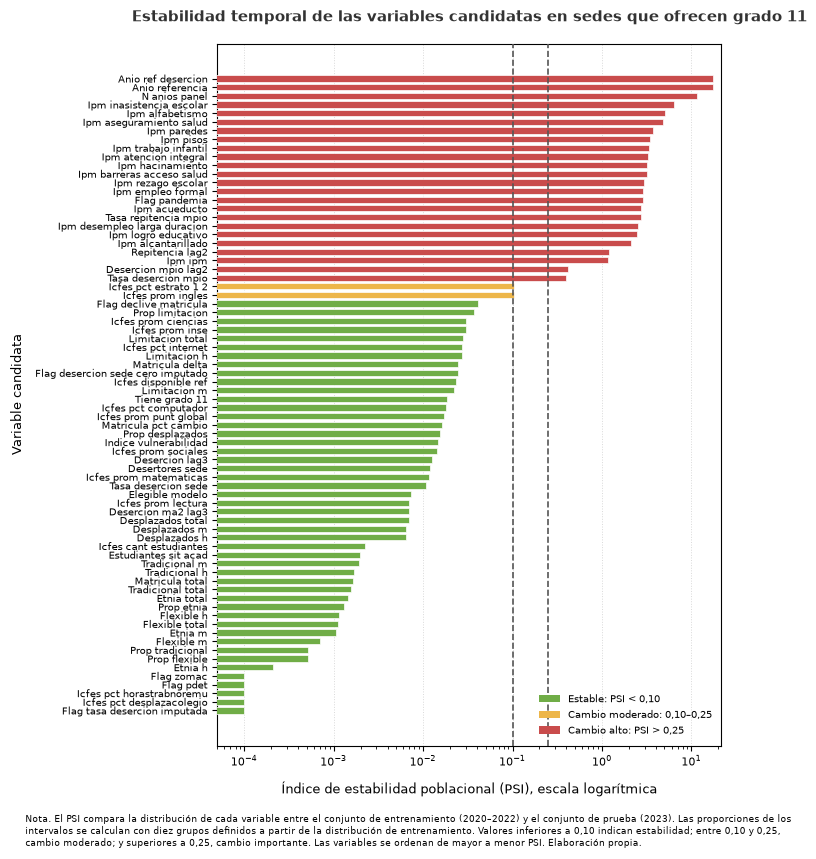


GENERANDO FIGURA PSI: SOLO_PRIMARIA

Panel: Solo_Primaria
Training years: [2020, 2021, 2022]
Test years: [2023]
Training observations: 121,729
Test observations: 40,499
Candidate variables: 59
Imagen guardada en: C:\Users\DELL\OneDrive\Escritorio\UNIVERSIDAD\Maestria Business A\Proyecto Empresarial\Figures\Grafs_Tables_Model\03_PSI_Candidatas_Solo_Primaria.png


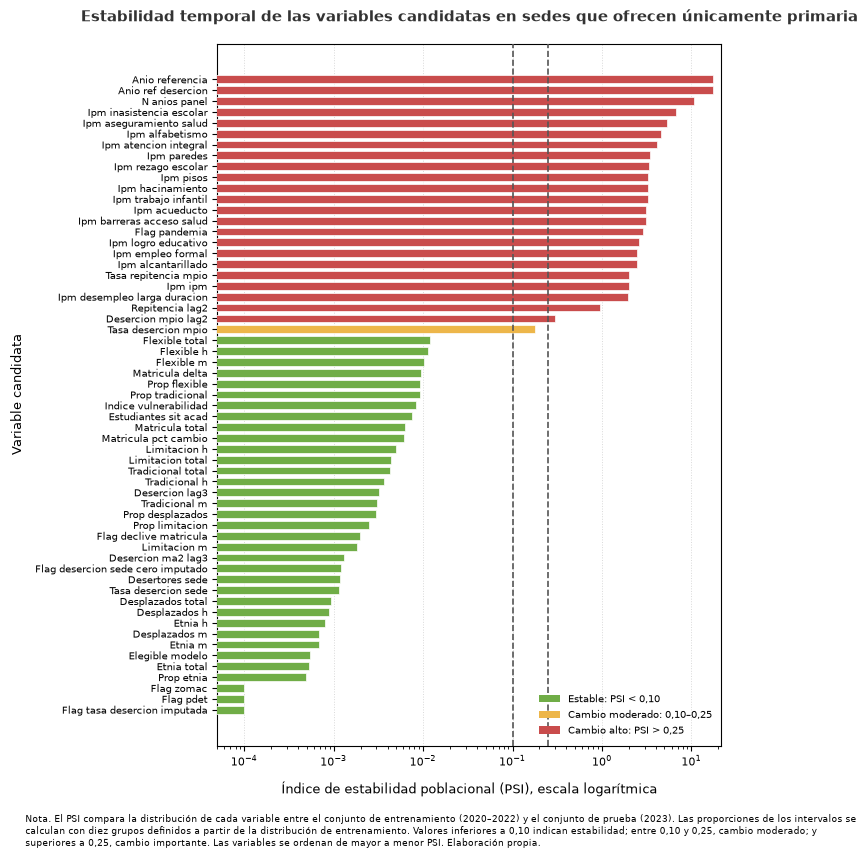


Proceso finalizado.
Las imágenes se guardaron en: C:\Users\DELL\OneDrive\Escritorio\UNIVERSIDAD\Maestria Business A\Proyecto Empresarial\Figures\Grafs_Tables_Model


In [10]:

# =============================================================================
# 00_COD_Other_Figures
# Figure 03 - PSI of candidate variables: TRAIN vs TEST
# =============================================================================

# =============================================================================
# 1. IMPORTS
# =============================================================================
from pathlib import Path
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import LogLocator, LogFormatterMathtext

warnings.filterwarnings("ignore")


# =============================================================================
# 2. PATHS
# =============================================================================
PROJECT_DIR = Path(
    r"C:\Users\DELL\OneDrive\Escritorio\UNIVERSIDAD\Maestria Business A\Proyecto Empresarial"
)

DATA_DIR = PROJECT_DIR / "Data" / "Processed"
AUDIT_DIR = DATA_DIR / "Auditoria_Panel"

OUTPUT_DIR = (
    PROJECT_DIR
    / "Figures"
    / "Grafs_Tables_Model"
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


# =============================================================================
# 3. GENERAL CONFIGURATION
# =============================================================================

# Panel master files
PANEL_FILES = {
    "Ofrecen11": DATA_DIR / "panel_maestro_ofrecen11.csv",
    "Solo_Primaria": DATA_DIR / "panel_maestro_Solo_Primaria.csv",
}

# Phase 1 audit files containing the candidate-variable universe
AUDIT_FILES = {
    "Ofrecen11": AUDIT_DIR / "ofrecen11_18_train_test_drift.csv",
    "Solo_Primaria": AUDIT_DIR / "solo_primaria_18_train_test_drift.csv",
}

# Relevant columns
YEAR_COL = "PERIODO_ANIO"
VARIABLE_COL = "variable"
PSI_AUDIT_COL = "psi_train_test"

# Requested temporal split
TRAIN_YEARS = [2020, 2021, 2022]
TEST_YEARS = [2023]

# PSI configuration
PSI_BINS = 10
MIN_OBSERVATIONS = 50
EPSILON = 1e-4

# PSI thresholds
PSI_STABLE = 0.10
PSI_MODERATE = 0.25

# Figure configuration
FIG_SIZE = (8, 9)
FIG_DPI = 300

COLORS = {
    "stable": "#70AD47",
    "moderate": "#EDB64A",
    "high": "#C94C4C",
    "threshold": "#555555",
    "grid": "#D9D9D9",
    "text": "#333333",
}

PANEL_TITLES = {
    "Ofrecen11": (
        "Estabilidad temporal de las variables candidatas "
        "en sedes que ofrecen grado 11"
    ),
    "Solo_Primaria": (
        "Estabilidad temporal de las variables candidatas "
        "en sedes que ofrecen únicamente primaria"
    ),
}


# =============================================================================
# 4. VARIABLE LABELS IN SPANISH
# =============================================================================

TERM_TRANSLATIONS = {
    "DESERCION": "Deserción",
    "MATRICULA": "Matrícula",
    "ESTUDIANTES": "Estudiantes",
    "DESPLAZADOS": "Personas desplazadas",
    "LIMITACION": "Personas con limitación",
    "TRADICIONAL": "Educación tradicional",
    "FLEXIBLE": "Educación flexible",
    "ETNIA": "Población étnica",
    "TASA": "Tasa",
    "PROM": "Promedio",
    "PUNT": "Puntaje",
    "GLOBAL": "Global",
    "LECTURA": "Lectura",
    "MATEMATICAS": "Matemáticas",
    "CIENCIAS": "Ciencias",
    "SOCIALES": "Sociales",
    "INGLES": "Inglés",
    "INDICE": "Índice",
    "VULNERABILIDAD": "Vulnerabilidad",
    "REPITENCIA": "Repitencia",
    "IPM": "Pobreza multidimensional",
    "PROP": "Proporción",
    "FLAG": "Indicador",
    "CAMBIO": "Cambio",
    "TOTAL": "Total",
    "PCT": "Porcentaje",
    "LAG": "Rezago",
    "PDET": "PDET",
    "ZOMAC": "ZOMAC",
    "PANDEMIA": "Pandemia",
    "TIENE": "Tiene",
    "GRADO": "Grado",
    "11": "11",
    "REF": "Referencia",
    "REGION": "Región",
    "MUNICIPIO": "Municipio",
}


def translate_variable_name(variable):
    """
    Convert variable names into readable Spanish labels.
    """
    name = str(variable).upper()

    # Replace known terms, prioritizing longer terms
    for term in sorted(TERM_TRANSLATIONS, key=len, reverse=True):
        name = re.sub(
            rf"\b{re.escape(term)}\b",
            TERM_TRANSLATIONS[term],
            name
        )

    # Replace underscores and normalize spaces
    name = name.replace("_", " ").strip()
    name = re.sub(r"\s+", " ", name)

    return name.capitalize()


# =============================================================================
# 5. PSI CALCULATION
# =============================================================================

def calculate_psi(train_series, test_series, bins=10):
    """
    Calculate Population Stability Index using training-based bins.
    The implementation follows the methodology used in the Phase 1 audit.
    """

    train = pd.to_numeric(train_series, errors="coerce").dropna()
    test = pd.to_numeric(test_series, errors="coerce").dropna()

    if len(train) < MIN_OBSERVATIONS or len(test) < MIN_OBSERVATIONS:
        return np.nan

    if train.nunique() <= bins:
        categories = sorted(set(train.unique()) | set(test.unique()))

        train_pct = (
            train.value_counts(normalize=True)
            .reindex(categories)
            .fillna(0)
            .to_numpy()
        )

        test_pct = (
            test.value_counts(normalize=True)
            .reindex(categories)
            .fillna(0)
            .to_numpy()
        )

    else:
        # Define quantile bins using the training distribution
        edges = np.unique(
            np.quantile(train, np.linspace(0, 1, bins + 1))
        )

        if len(edges) < 3:
            return np.nan

        edges[0] = -np.inf
        edges[-1] = np.inf

        train_pct = np.histogram(train, bins=edges)[0] / len(train)
        test_pct = np.histogram(test, bins=edges)[0] / len(test)

    # Avoid zero proportions in the logarithm
    train_pct = np.clip(train_pct, EPSILON, None)
    test_pct = np.clip(test_pct, EPSILON, None)

    psi_value = np.sum(
        (test_pct - train_pct)
        * np.log(test_pct / train_pct)
    )

    return float(psi_value)


# =============================================================================
# 6. DATA LOADING AND VALIDATION
# =============================================================================

def load_panel_and_candidates(panel_label):
    """
    Load the panel master and the Phase 1 audit.
    The audit supplies the candidate-variable universe.
    """

    panel_path = PANEL_FILES[panel_label]
    audit_path = AUDIT_FILES[panel_label]

    if not panel_path.exists():
        raise FileNotFoundError(
            f"No se encontró el panel maestro: {panel_path}"
        )

    if not audit_path.exists():
        raise FileNotFoundError(
            f"No se encontró el archivo de auditoría: {audit_path}"
        )

    panel = pd.read_csv(
        panel_path,
        encoding="utf-8-sig",
        low_memory=False
    )

    audit = pd.read_csv(
        audit_path,
        encoding="utf-8-sig",
        low_memory=False
    )

    # Validate required columns
    required_panel = [YEAR_COL]
    required_audit = [VARIABLE_COL, PSI_AUDIT_COL]

    missing_panel = [
        col for col in required_panel if col not in panel.columns
    ]

    missing_audit = [
        col for col in required_audit if col not in audit.columns
    ]

    if missing_panel:
        raise ValueError(
            f"{panel_label}: faltan columnas en el panel: {missing_panel}"
        )

    if missing_audit:
        raise ValueError(
            f"{panel_label}: faltan columnas en la auditoría: {missing_audit}"
        )

    # Convert year to numeric
    panel[YEAR_COL] = pd.to_numeric(
        panel[YEAR_COL],
        errors="coerce"
    )

    # Recover candidate variables from the Phase 1 audit
    candidates = (
        audit[VARIABLE_COL]
        .dropna()
        .astype(str)
        .drop_duplicates()
        .tolist()
    )

    # Keep only variables that still exist in the master panel
    candidates = [
        col for col in candidates
        if col in panel.columns
        and pd.api.types.is_numeric_dtype(panel[col])
    ]

    if not candidates:
        raise ValueError(
            f"{panel_label}: no se encontraron variables candidatas "
            "numéricas comunes entre la auditoría y el panel maestro."
        )

    # Define exact training and test samples by target year
    train = panel.loc[
        panel[YEAR_COL].isin(TRAIN_YEARS)
    ].copy()

    test = panel.loc[
        panel[YEAR_COL].isin(TEST_YEARS)
    ].copy()

    if train.empty or test.empty:
        raise ValueError(
            f"{panel_label}: no hay observaciones suficientes "
            "para los años de entrenamiento o prueba."
        )

    print(f"\nPanel: {panel_label}")
    print(f"Training years: {TRAIN_YEARS}")
    print(f"Test years: {TEST_YEARS}")
    print(f"Training observations: {len(train):,}")
    print(f"Test observations: {len(test):,}")
    print(f"Candidate variables: {len(candidates):,}")

    return train, test, candidates


# =============================================================================
# 7. CALCULATE PSI FOR ALL CANDIDATE VARIABLES
# =============================================================================

def calculate_panel_psi(panel_label):
    """
    Calculate PSI for every candidate variable using the requested years.
    """

    train, test, candidates = load_panel_and_candidates(panel_label)

    results = []

    for variable in candidates:

        psi_value = calculate_psi(
            train[variable],
            test[variable],
            bins=PSI_BINS
        )

        results.append({
            "variable": variable,
            "label": translate_variable_name(variable),
            "psi": psi_value,
        })

    results_df = pd.DataFrame(results)

    # Remove variables for which PSI could not be calculated
    results_df = results_df.dropna(subset=["psi"]).copy()

    if results_df.empty:
        raise ValueError(
            f"{panel_label}: no fue posible calcular el PSI "
            "para ninguna variable candidata."
        )

    # Sort from highest to lowest PSI
    results_df = results_df.sort_values(
        "psi",
        ascending=False
    ).reset_index(drop=True)

    return results_df


# =============================================================================
# 8. PLOT PSI
# =============================================================================

def plot_psi(results_df, panel_label):
    """
    Generate and save the horizontal PSI bar chart.
    """

    plot_df = results_df.copy()

    # Use a small positive value for zero PSI observations on the log axis
    plot_df["psi_plot"] = plot_df["psi"].clip(lower=EPSILON)

    # Assign colors according to PSI thresholds
    def assign_color(value):
        if value < PSI_STABLE:
            return COLORS["stable"]
        elif value <= PSI_MODERATE:
            return COLORS["moderate"]
        return COLORS["high"]

    plot_df["color"] = plot_df["psi"].apply(assign_color)

    # Reverse order so the highest PSI appears at the top
    plot_df = plot_df.iloc[::-1].reset_index(drop=True)

    fig, ax = plt.subplots(figsize=FIG_SIZE)

    ax.barh(
        y=plot_df["label"],
        width=plot_df["psi_plot"],
        color=plot_df["color"],
        edgecolor="white",
        linewidth=0.5,
        height=0.72,
        zorder=3
    )

    # Logarithmic x-axis
    ax.set_xscale("log")

    positive_values = plot_df["psi_plot"].to_numpy()
    x_min = min(EPSILON, positive_values.min() * 0.5)
    x_max = max(positive_values.max() * 1.25, 0.30)

    ax.set_xlim(left=x_min, right=x_max)

    # PSI threshold lines
    ax.axvline(
        PSI_STABLE,
        color=COLORS["threshold"],
        linestyle="--",
        linewidth=1.2,
        zorder=4
    )

    ax.axvline(
        PSI_MODERATE,
        color=COLORS["threshold"],
        linestyle="--",
        linewidth=1.2,
        zorder=4
    )

    # Labels and title
    ax.set_title(
        PANEL_TITLES[panel_label],
        fontsize=11,
        fontweight="bold",
        pad=16,
        color=COLORS["text"]
    )

    ax.set_xlabel(
        "Índice de estabilidad poblacional (PSI), escala logarítmica",
        fontsize=9,
        labelpad=9
    )

    ax.set_ylabel(
        "Variable candidata",
        fontsize=9,
        labelpad=8
    )

    ax.tick_params(
        axis="y",
        labelsize=7.5
    )

    ax.tick_params(
        axis="x",
        labelsize=8
    )

    # Logarithmic ticks
    ax.xaxis.set_major_locator(
        LogLocator(base=10)
    )

    ax.xaxis.set_major_formatter(
        LogFormatterMathtext(base=10)
    )

    # Grid
    ax.grid(
        axis="x",
        which="major",
        linestyle=":",
        linewidth=0.7,
        color=COLORS["grid"],
        zorder=0
    )

    ax.set_axisbelow(True)

    # Legend
    from matplotlib.patches import Patch

    legend_elements = [
        Patch(
            facecolor=COLORS["stable"],
            label="Estable: PSI < 0,10"
        ),
        Patch(
            facecolor=COLORS["moderate"],
            label="Cambio moderado: 0,10–0,25"
        ),
        Patch(
            facecolor=COLORS["high"],
            label="Cambio alto: PSI > 0,25"
        ),
    ]

    ax.legend(
        handles=legend_elements,
        loc="lower right",
        frameon=False,
        fontsize=7.5
    )

    # Figure note
    fig.text(
        0.10,
        0.015,
        (
            "Nota. El PSI compara la distribución de cada variable entre "
            "el conjunto de entrenamiento (2020–2022) y el conjunto de "
            "prueba (2023). Las proporciones de los intervalos se calculan "
            "con diez grupos definidos a partir de la distribución de "
            "entrenamiento. Valores inferiores a 0,10 indican estabilidad; "
            "entre 0,10 y 0,25, cambio moderado; y superiores a 0,25, "
            "cambio importante. Las variables se ordenan de mayor a menor "
            "PSI. Elaboración propia."
        ),
        ha="left",
        va="bottom",
        fontsize=6.5,
        wrap=True
    )

    # Layout
    fig.subplots_adjust(
        left=0.34,
        right=0.97,
        top=0.91,
        bottom=0.13
    )

    # Save figure
    output_file = (
        OUTPUT_DIR
        / f"03_PSI_Candidatas_{panel_label}.png"
    )

    fig.savefig(
        output_file,
        dpi=FIG_DPI,
        bbox_inches="tight",
        facecolor="white"
    )

    print(f"Imagen guardada en: {output_file}")

    # Display figure in the execution output
    plt.show()

    plt.close(fig)


# =============================================================================
# 9. MAIN EXECUTION
# =============================================================================

def main():

    for panel_label in PANEL_FILES:

        print("\n" + "=" * 75)
        print(f"GENERANDO FIGURA PSI: {panel_label.upper()}")
        print("=" * 75)

        results_df = calculate_panel_psi(panel_label)

        plot_psi(
            results_df=results_df,
            panel_label=panel_label
        )

    print("\nProceso finalizado.")
    print(f"Las imágenes se guardaron en: {OUTPUT_DIR}")


if __name__ == "__main__":
    main()


NO EN DOC: gráfico clásico de cuatro componentes para cada variable importante de los dos paneles: Observed, Trend, Seasonal y Random.

In [ ]:

# ============================================================
# 00_COD_Other_Figures_Decomposition.py
# Four-component descriptive decomposition: 2017-2024
# ============================================================

# 1. LIBRARIES
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from statsmodels.nonparametric.smoothers_lowess import lowess


# ============================================================
# 2. PATHS
# ============================================================

BASE_DIR = Path(
    r"C:\Users\DELL\OneDrive\Escritorio\UNIVERSIDAD\Maestria Business A\Proyecto Empresarial"
)

DATA_DIR = BASE_DIR / "Data" / "Processed"

OUTPUT_DIR = (
    BASE_DIR / "Figures" / "Grafs_Tables_Model"
    / "Descomposicion_2017_2024"
)

FILES = {
    "Ofrecen11": DATA_DIR / "panel_maestro_ofrecen11.csv",
    "Solo_Primaria": DATA_DIR / "panel_maestro_Solo_Primaria.csv"
}


# ============================================================
# 3. CONFIGURATION
# ============================================================

YEAR_COL = "PERIODO_ANIO"

START_YEAR = 2017
END_YEAR = 2024

MIN_VALID_YEARS = 5
LOWESS_FRAC = 0.65
DPI = 300

# Student exposure used to aggregate observations.
# The master panels are expected to contain ESTUDIANTES_SIT_ACAD.
WEIGHT_COL = "ESTUDIANTES_SIT_ACAD"

VARIABLES = [
    "TASA_DESERCION_SEDE",
    "DESERCION_LAG3",
    "MATRICULA_TOTAL",
    "MATRICULA_PCT_CAMBIO",
    "PROP_DESPLAZADOS",
    "PROP_LIMITACION",
    "PROP_ETNIA",
    "PROP_FLEXIBLE"
]

# Additional variables available in Ofrecen11.
OFFER_VARIABLES = [
    "ICFES_PROM_PUNT_GLOBAL",
    "ICFES_PROM_INSE"
]

LABELS = {
    "TASA_DESERCION_SEDE": "Tasa de deserción de la sede",
    "DESERCION_LAG3": "Deserción rezagada (t-3)",
    "MATRICULA_TOTAL": "Matrícula total",
    "MATRICULA_PCT_CAMBIO": "Cambio porcentual de matrícula",
    "PROP_DESPLAZADOS": "Proporción de estudiantes desplazados",
    "PROP_LIMITACION": "Proporción de estudiantes con limitación",
    "PROP_ETNIA": "Proporción de estudiantes de grupos étnicos",
    "PROP_FLEXIBLE": "Proporción de matrícula flexible",
    "ICFES_PROM_PUNT_GLOBAL": "Puntaje global promedio ICFES",
    "ICFES_PROM_INSE": "INSE promedio ICFES"
}

COLORS = {
    "Ofrecen11": "#245B8F",
    "Solo_Primaria": "#A65E2E"
}


# ============================================================
# 4. FUNCTIONS
# ============================================================

def read_data(path):
    """Load and filter the annual panel."""

    if not path.exists():
        raise FileNotFoundError(f"File not found: {path}")

    try:
        df = pd.read_csv(path, low_memory=False)
    except UnicodeDecodeError:
        df = pd.read_csv(
            path,
            encoding="latin-1",
            low_memory=False
        )

    required = [YEAR_COL]

    missing = [c for c in required if c not in df.columns]

    if missing:
        raise ValueError(f"Missing required columns: {missing}")

    df[YEAR_COL] = pd.to_numeric(
        df[YEAR_COL],
        errors="coerce"
    )

    df = df[
        df[YEAR_COL].between(START_YEAR, END_YEAR)
    ].copy()

    df[YEAR_COL] = df[YEAR_COL].astype(int)

    return df


def calculate_annual_series(df, variable):
    """
    Calculate annual averages.
    Use student-weighted averages when the student count is available.
    """

    if variable not in df.columns:
        return None, None

    cols = [YEAR_COL, variable]

    use_weights = WEIGHT_COL in df.columns

    if use_weights:
        cols.append(WEIGHT_COL)

    data = df[cols].copy()

    data[variable] = pd.to_numeric(
        data[variable],
        errors="coerce"
    )

    if use_weights:
        data[WEIGHT_COL] = pd.to_numeric(
            data[WEIGHT_COL],
            errors="coerce"
        )

        data = data[
            (data[WEIGHT_COL] > 0) &
            data[WEIGHT_COL].notna() &
            data[variable].notna()
        ]

        def weighted_mean(group):
            return np.average(
                group[variable],
                weights=group[WEIGHT_COL]
            )

        annual = data.groupby(
            YEAR_COL
        ).apply(weighted_mean)

        aggregation = f"Ponderado por {WEIGHT_COL}"

    else:
        data = data.dropna(subset=[variable])

        annual = data.groupby(
            YEAR_COL
        )[variable].mean()

        aggregation = "Promedio simple por sede"

    annual = annual.reindex(
        range(START_YEAR, END_YEAR + 1)
    )

    annual.index.name = "ANIO"

    return annual.astype(float), aggregation


def calculate_components(series):
    """
    Estimate trend using LOWESS.
    Random component is observed minus trend.
    Seasonal component cannot be identified from annual data.
    """

    observed = series.dropna()

    if len(observed) < MIN_VALID_YEARS:
        return None

    years = observed.index.to_numpy(dtype=float)
    values = observed.to_numpy(dtype=float)

    trend_values = lowess(
        endog=values,
        exog=years,
        frac=LOWESS_FRAC,
        it=0,
        return_sorted=False
    )

    trend = pd.Series(
        trend_values,
        index=observed.index
    )

    random = observed - trend

    result = pd.DataFrame(index=series.index)

    result["Observed"] = series
    result["Trend"] = np.nan
    result["Seasonal"] = np.nan
    result["Random"] = np.nan

    result.loc[observed.index, "Trend"] = trend
    result.loc[observed.index, "Random"] = random

    return result


def plot_decomposition(
    panel,
    variable,
    components,
    aggregation
):
    """Generate the classical four-panel decomposition figure."""

    color = COLORS[panel]

    label = LABELS.get(
        variable,
        variable
    )

    years = components.index.to_numpy()

    fig, axes = plt.subplots(
        4,
        1,
        figsize=(12, 9),
        sharex=True,
        gridspec_kw={
            "height_ratios": [1.3, 1, 0.8, 1]
        }
    )

    fig.patch.set_facecolor("white")

    # --------------------------------------------------------
    # OBSERVED
    # --------------------------------------------------------

    axes[0].plot(
        years,
        components["Observed"],
        marker="o",
        linewidth=2,
        color=color
    )

    axes[0].set_title(
        "Observed",
        loc="left",
        fontweight="bold"
    )

    axes[0].set_ylabel("Valor observado")

    # --------------------------------------------------------
    # TREND
    # --------------------------------------------------------

    axes[1].plot(
        years,
        components["Trend"],
        linewidth=2.5,
        color=color
    )

    axes[1].set_title(
        "Trend",
        loc="left",
        fontweight="bold"
    )

    axes[1].set_ylabel("Tendencia")

    # --------------------------------------------------------
    # SEASONAL
    # --------------------------------------------------------

    axes[2].axhline(
        0,
        color="gray",
        linewidth=1
    )

    axes[2].text(
        0.5,
        0.5,
        "No identificable con datos anuales\n"
        "Se requieren observaciones mensuales o trimestrales",
        transform=axes[2].transAxes,
        ha="center",
        va="center",
        fontsize=10
    )

    axes[2].set_title(
        "Seasonal",
        loc="left",
        fontweight="bold"
    )

    axes[2].set_yticks([])

    # --------------------------------------------------------
    # RANDOM / IRREGULAR
    # --------------------------------------------------------

    axes[3].axhline(
        0,
        color="gray",
        linewidth=1
    )

    axes[3].plot(
        years,
        components["Random"],
        marker="o",
        linewidth=1.8,
        color=color
    )

    axes[3].set_title(
        "Random / Irregular",
        loc="left",
        fontweight="bold"
    )

    axes[3].set_ylabel("Residuo")
    axes[3].set_xlabel("Año")

    # --------------------------------------------------------
    # GENERAL FORMATTING
    # --------------------------------------------------------

    for ax in axes:

        ax.set_xlim(
            START_YEAR - 0.2,
            END_YEAR + 0.2
        )

        ax.set_xticks(
            range(START_YEAR, END_YEAR + 1)
        )

        ax.grid(
            axis="y",
            alpha=0.25
        )

        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)

    fig.suptitle(
        f"{label}\nPanel {panel} | 2017-2024",
        fontsize=14,
        fontweight="bold"
    )

    fig.text(
        0.01,
        0.005,
        f"Agregación: {aggregation}. "
        "Trend: suavizamiento LOWESS. "
        "Random: observado menos tendencia.",
        fontsize=8,
        color="dimgray"
    )

    plt.tight_layout(
        rect=[0, 0.035, 1, 0.94]
    )

    # --------------------------------------------------------
    # SAVE PNG AND CSV
    # --------------------------------------------------------

    output_panel = OUTPUT_DIR / panel

    output_panel.mkdir(
        parents=True,
        exist_ok=True
    )

    stem = (
        f"Decomposition_{panel}_{variable}"
    )

    png_path = output_panel / f"{stem}.png"
    csv_path = output_panel / f"{stem}.csv"

    last_error = None

    for attempt in range(3):

        try:

            fig.savefig(
                png_path,
                dpi=DPI,
                bbox_inches="tight",
                facecolor="white"
            )

            last_error = None
            break

        except OSError as exc:

            last_error = exc

            warnings.warn(
                f"Save attempt {attempt + 1} failed: {exc}"
            )

    if last_error is not None:

        fallback = (
            Path.home()
            / "AppData"
            / "Local"
            / "Auditoria_Figuras"
            / panel
        )

        fallback.mkdir(
            parents=True,
            exist_ok=True
        )

        png_path = fallback / f"{stem}.png"
        csv_path = fallback / f"{stem}.csv"

        fig.savefig(
            png_path,
            dpi=DPI,
            bbox_inches="tight",
            facecolor="white"
        )

    components.rename_axis(
        "ANIO"
    ).to_csv(
        csv_path,
        encoding="utf-8-sig"
    )

    plt.close(fig)

    return png_path, csv_path


def process_panel(panel, path):
    """Generate figures for all available variables."""

    df = read_data(path)

    variables = VARIABLES.copy()

    if panel == "Ofrecen11":
        variables.extend(OFFER_VARIABLES)

    print("\n" + "=" * 60)
    print(f"PROCESANDO PANEL: {panel}")
    print("=" * 60)

    generated = 0

    for variable in variables:

        if variable not in df.columns:

            print(
                f"[OMITIDA] {variable}: columna no disponible"
            )

            continue

        try:

            series, aggregation = calculate_annual_series(
                df,
                variable
            )

            if series is None:
                continue

            valid_years = series.notna().sum()

            if valid_years < MIN_VALID_YEARS:

                print(
                    f"[OMITIDA] {variable}: "
                    f"solo {valid_years} años disponibles"
                )

                continue

            components = calculate_components(
                series
            )

            if components is None:
                continue

            png, csv = plot_decomposition(
                panel,
                variable,
                components,
                aggregation
            )

            generated += 1

            print(
                f"[OK] {variable} | "
                f"{valid_years} años | {png}"
            )

        except Exception as exc:

            print(
                f"[ERROR] {variable}: {exc}"
            )

    print(
        f"\nFiguras generadas para {panel}: {generated}"
    )


# ============================================================
# 5. EXECUTION
# ============================================================

def main():

    OUTPUT_DIR.mkdir(
        parents=True,
        exist_ok=True
    )

    for panel, path in FILES.items():

        try:

            process_panel(
                panel,
                path
            )

        except Exception as exc:

            print(
                f"[ERROR PANEL] {panel}: {exc}"
            )

    print("\nProceso finalizado.")
    print(f"Resultados guardados en: {OUTPUT_DIR}")


if __name__ == "__main__":
    main()



PROCESANDO PANEL: Ofrecen11
[OK] TASA_DESERCION_SEDE | 7 años | C:\Users\DELL\OneDrive\Escritorio\UNIVERSIDAD\Maestria Business A\Proyecto Empresarial\Figures\Grafs_Tables_Model\Descomposicion_2017_2024\Ofrecen11\Decomposition_Ofrecen11_TASA_DESERCION_SEDE.png
[OMITIDA] DESERCION_LAG3: solo 4 años disponibles
[OK] MATRICULA_TOTAL | 7 años | C:\Users\DELL\OneDrive\Escritorio\UNIVERSIDAD\Maestria Business A\Proyecto Empresarial\Figures\Grafs_Tables_Model\Descomposicion_2017_2024\Ofrecen11\Decomposition_Ofrecen11_MATRICULA_TOTAL.png
[OK] MATRICULA_PCT_CAMBIO | 6 años | C:\Users\DELL\OneDrive\Escritorio\UNIVERSIDAD\Maestria Business A\Proyecto Empresarial\Figures\Grafs_Tables_Model\Descomposicion_2017_2024\Ofrecen11\Decomposition_Ofrecen11_MATRICULA_PCT_CAMBIO.png
[OK] PROP_DESPLAZADOS | 7 años | C:\Users\DELL\OneDrive\Escritorio\UNIVERSIDAD\Maestria Business A\Proyecto Empresarial\Figures\Grafs_Tables_Model\Descomposicion_2017_2024\Ofrecen11\Decomposition_Ofrecen11_PROP_DESPLAZADOS.png
[

: 

Compromiso entre captura total % y captura Q1 contra valor de α

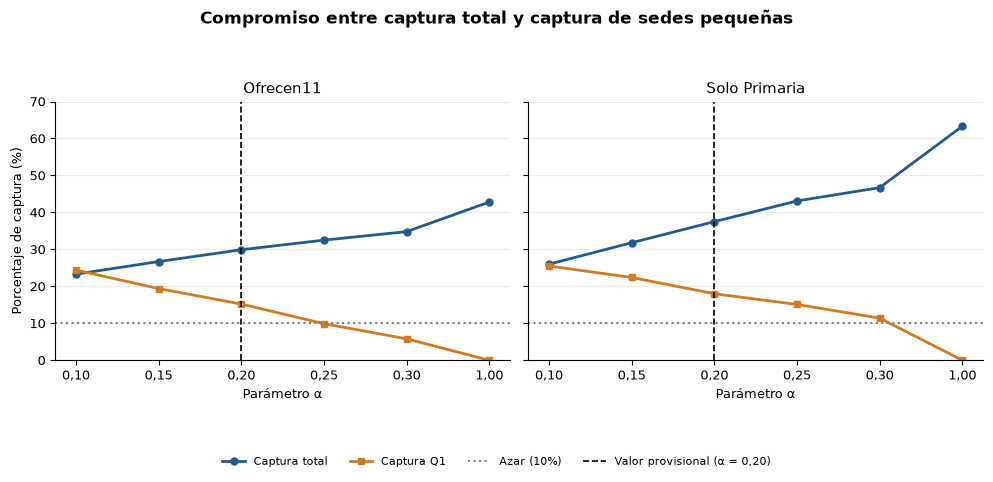

Figura guardada en: C:\Users\DELL\OneDrive\Escritorio\UNIVERSIDAD\Maestria Business A\Proyecto Empresarial\Figures\Grafs_Tables_Model\Figura_Compromiso_Captura_Alpha.png


In [1]:

from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. OUTPUT
# ------------------------------------------------------------

OUTPUT_DIR = Path(
    r"C:\Users\DELL\OneDrive\Escritorio\UNIVERSIDAD\Maestria Business A\Proyecto Empresarial\Figures\Grafs_Tables_Model"
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

OUTPUT_FILE = OUTPUT_DIR / "Figura_Compromiso_Captura_Alpha.png"

# ------------------------------------------------------------
# 2. DATA
# ------------------------------------------------------------

alpha = ["0,10", "0,15", "0,20", "0,25", "0,30", "1,00"]
x = np.arange(len(alpha))

data = {
    "Ofrecen11": {
        "Captura total": [23.3, 26.7, 29.9, 32.5, 34.8, 42.8],
        "Captura Q1": [24.4, 19.4, 15.2, 9.9, 5.8, 0.0]
    },
    "Solo_Primaria": {
        "Captura total": [26.0, 31.8, 37.5, 43.1, 46.7, 63.3],
        "Captura Q1": [25.5, 22.4, 18.0, 15.1, 11.4, 0.0]
    }
}

# ------------------------------------------------------------
# 3. PLOT
# ------------------------------------------------------------

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.size": 9,
    "axes.titlesize": 11,
    "axes.labelsize": 9,
    "legend.fontsize": 8
})

fig, axes = plt.subplots(
    1, 2,
    figsize=(10, 4.5),
    sharey=True
)

colors = {
    "Captura total": "#245B8F",
    "Captura Q1": "#D17A22"
}

markers = {
    "Captura total": "o",
    "Captura Q1": "s"
}

for ax, (panel, values) in zip(axes, data.items()):

    for series_name, series_values in values.items():

        ax.plot(
            x,
            series_values,
            label=series_name,
            color=colors[series_name],
            marker=markers[series_name],
            linewidth=2,
            markersize=5
        )

    # Random selection benchmark
    ax.axhline(
        10,
        color="gray",
        linestyle=":",
        linewidth=1.5,
        label="Azar (10%)"
    )

    # Provisional alpha
    ax.axvline(
        2,
        color="black",
        linestyle="--",
        linewidth=1.2,
        label="Valor provisional (α = 0,20)"
    )

    ax.set_title(panel.replace("_", " "))
    ax.set_xticks(x)
    ax.set_xticklabels(alpha)
    ax.set_xlabel("Parámetro α")
    ax.set_ylim(0, 70)

    ax.grid(
        axis="y",
        alpha=0.25
    )

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

axes[0].set_ylabel("Porcentaje de captura (%)")

# Shared legend
handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="lower center",
    ncol=4,
    frameon=False,
    bbox_to_anchor=(0.5, -0.02)
)

fig.suptitle(
    "Compromiso entre captura total y captura de sedes pequeñas",
    fontsize=12,
    fontweight="bold",
    y=1.02
)

fig.tight_layout(
    rect=[0, 0.12, 1, 0.96]
)

fig.savefig(
    OUTPUT_FILE,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()
plt.close(fig)

print(f"Figura guardada en: {OUTPUT_FILE}")
